In [10]:
import pandas as pd

# Define column names based on the UCI Heart Disease Cleveland dataset description
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal', 'target'
]

# Load the dataset, specifying column names and handling missing values ('?')
df = pd.read_csv(
    '/processed.cleveland.data',
    names=columns,
    na_values='?'
)

print("DataFrame loaded successfully. Displaying the first 5 rows:")
print(df.head())

print("\nDataFrame Info:")
df.info()

print("\nMissing values count:")
print(df.isnull().sum())

DataFrame loaded successfully. Displaying the first 5 rows:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 

In [11]:
print("Missing values before imputation:")
print(df[['ca', 'thal']].isnull().sum())

# Impute missing values in 'ca' with its mode
ca_mode = df['ca'].mode()[0]
df['ca'] = df['ca'].fillna(ca_mode)

# Impute missing values in 'thal' with its mode
thal_mode = df['thal'].mode()[0]
df['thal'] = df['thal'].fillna(thal_mode)

print("\nMissing values after imputation:")
print(df[['ca', 'thal']].isnull().sum())

print("\nDataFrame Info after imputation:")
df.info()

Missing values before imputation:
ca      4
thal    2
dtype: int64

Missing values after imputation:
ca      0
thal    0
dtype: int64

DataFrame Info after imputation:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    float64
 12  thal      303 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [12]:
print("Original target column value counts:")
print(df['target'].value_counts())

# Encode the 'target' column to a binary format
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

print(
    "\nTransformed target column value counts (0: no disease, 1: disease present):"
)
print(df['target'].value_counts())

Original target column value counts:
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Transformed target column value counts (0: no disease, 1: disease present):
target
0    164
1    139
Name: count, dtype: int64


## Split Data

### Subtask:
Divide the processed dataset into training and testing sets using an 80/20 ratio. Ensure that the split is stratified based on the target variable and shuffled to maintain data distribution integrity.


In [13]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df.drop('target', axis=1)
y = df['target']

# Split the data into training and testing sets (80/20 ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Shapes of the resulting datasets:")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

print("\nValue counts for y_train (stratified split check):")
print(y_train.value_counts(normalize=True))
print("\nValue counts for y_test (stratified split check):")
print(y_test.value_counts(normalize=True))

Shapes of the resulting datasets:
X_train shape: (242, 13)
X_test shape: (61, 13)
y_train shape: (242,)
y_test shape: (61,)

Value counts for y_train (stratified split check):
target
0    0.541322
1    0.458678
Name: proportion, dtype: float64

Value counts for y_test (stratified split check):
target
0    0.540984
1    0.459016
Name: proportion, dtype: float64


## Train Decision Tree Model

### Subtask:
Initialize and train a Decision Tree Classifier using the training data. The model should use 'entropy' as the criterion for splitting, adhering to the ID3 principle, and an initial `max_depth` will be chosen for demonstration.


In [14]:
from sklearn.tree import DecisionTreeClassifier

# Instantiate the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(
    criterion='entropy', random_state=42, max_depth=3
)

# Train the Decision Tree model
dt_classifier.fit(X_train, y_train)

print("Decision Tree Classifier trained successfully with criterion='entropy' and max_depth=3.")

Decision Tree Classifier trained successfully with criterion='entropy' and max_depth=3.


## Evaluate Model Performance

### Subtask:
Assess the performance of the trained Decision Tree model on the test set. Calculate and display key evaluation metrics: Confusion Matrix, Accuracy, Precision, Recall, and F1-score. Include comments for each metric explaining its significance.


In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Make predictions on the test set
y_pred = dt_classifier.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print("Model Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f} - Proportion of correctly classified instances.")
print(f"Precision: {precision:.4f} - Proportion of positive identifications that were actually correct.")
print(f"Recall: {recall:.4f} - Proportion of actual positives that were identified correctly.")
print(f"F1-Score: {f1:.4f} - Harmonic mean of precision and recall, providing a single metric that balances both.")
print("Confusion Matrix:")
print(conf_matrix)


Model Evaluation Metrics:
Accuracy: 0.8033 - Proportion of correctly classified instances.
Precision: 0.7667 - Proportion of positive identifications that were actually correct.
Recall: 0.8214 - Proportion of actual positives that were identified correctly.
F1-Score: 0.7931 - Harmonic mean of precision and recall, providing a single metric that balances both.
Confusion Matrix:
[[26  7]
 [ 5 23]]


## Visualize Decision Tree

### Subtask:
Generate a clear and interpretable diagram of the trained Decision Tree. This visualization will help in understanding the decision-making process of the model. Ensure the plot is well-labeled and easy to read.


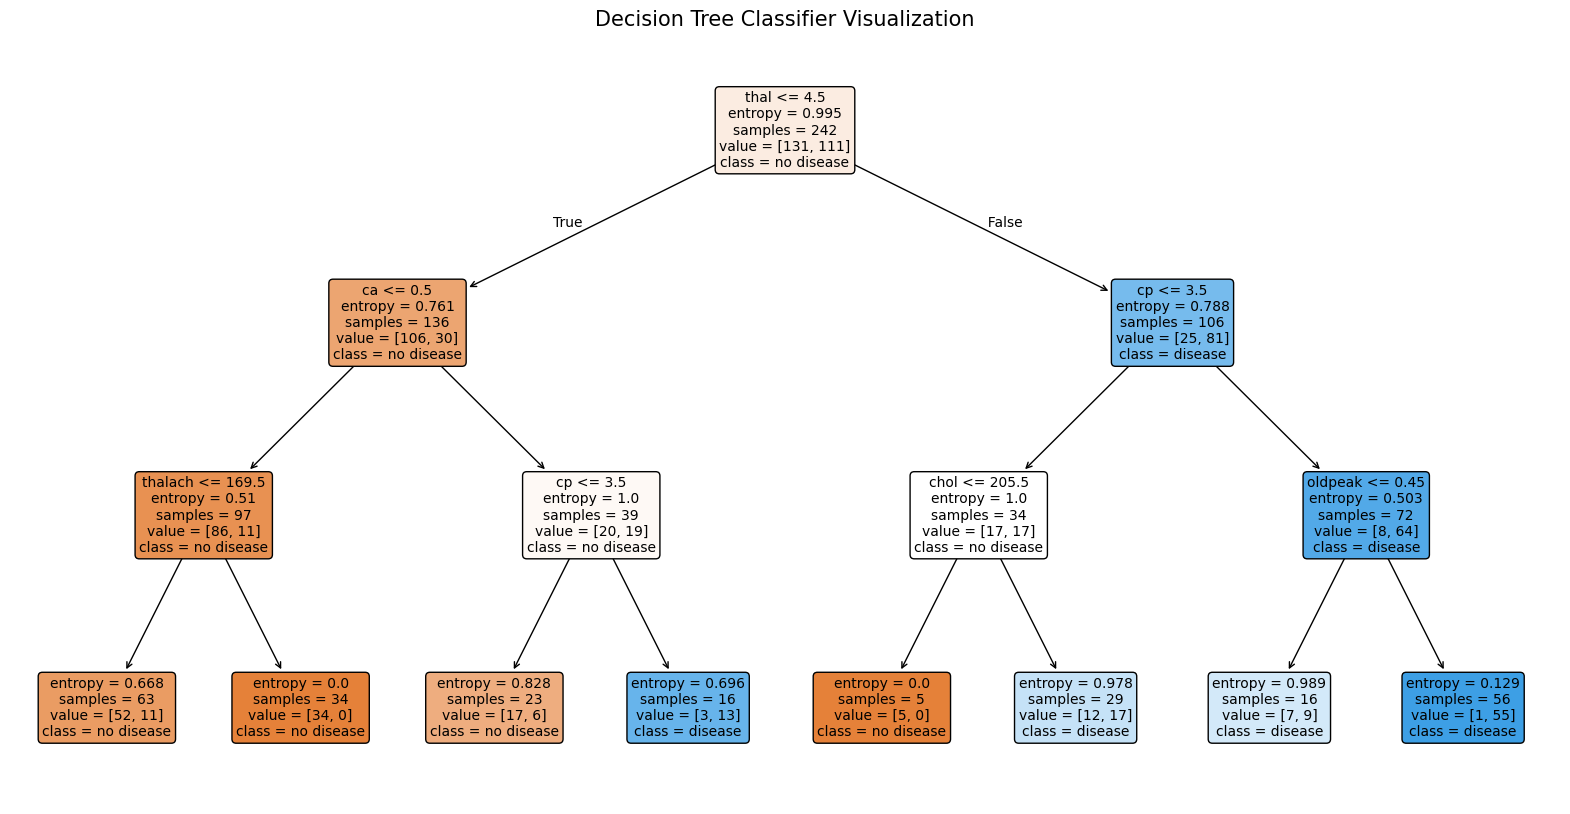

In [18]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Create a figure and an axes object for the plot
plt.figure(figsize=(20, 10))

# Plot the decision tree
plot_tree(
    dt_classifier,
    feature_names=X.columns.tolist(),
    class_names=['no disease', 'disease'],
    filled=True,
    rounded=True,
    fontsize=10
)

# Add a title to the plot
plt.title('Decision Tree Classifier Visualization', fontsize=15)

# Display the plot
plt.show()


## Hyperparameter Tuning (max_depth)

### Subtask:
Demonstrate how to experiment with different `max_depth` values for the Decision Tree. This step will involve retraining the model with varying depths and observing their impact on the evaluation metrics to illustrate hyperparameter tuning.


In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Define a range of max_depth values to experiment with
max_depth_values = range(1, 11)  # From 1 to 10

# Initialize a dictionary to store accuracy scores
accuracy_scores = {}

print("Experimenting with different max_depth values:\n")

for depth in max_depth_values:
    # Instantiate a Decision Tree Classifier with the current max_depth
    dt_classifier_tuned = DecisionTreeClassifier(
        criterion='entropy', random_state=42, max_depth=depth
    )

    # Train the model
    dt_classifier_tuned.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred_tuned = dt_classifier_tuned.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred_tuned)

    # Store the accuracy score
    accuracy_scores[depth] = accuracy

    print(f"Max_depth: {depth}, Accuracy: {accuracy:.4f}")


Experimenting with different max_depth values:

Max_depth: 1, Accuracy: 0.7213
Max_depth: 2, Accuracy: 0.7705
Max_depth: 3, Accuracy: 0.8033
Max_depth: 4, Accuracy: 0.7869
Max_depth: 5, Accuracy: 0.7869
Max_depth: 6, Accuracy: 0.7213
Max_depth: 7, Accuracy: 0.7869
Max_depth: 8, Accuracy: 0.7213
Max_depth: 9, Accuracy: 0.8033
Max_depth: 10, Accuracy: 0.8033
